In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import joblib

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Locate prepared dataset folder
output_dir = Path.cwd() / "Sonar_Mines_vs_Rocks"

if not output_dir.exists():
    matches = list(Path.cwd().rglob("X_train_scaled.csv"))
    if not matches:
        raise FileNotFoundError("Prepared training data not found.")
    output_dir = matches[0].parent

# Load prepared features and labels
X_train = pd.read_csv(output_dir / "X_train_scaled.csv")
X_test = pd.read_csv(output_dir / "X_test_scaled.csv")

y_train = pd.read_csv(output_dir / "y_train.csv")["Class"]
y_test = pd.read_csv(output_dir / "y_test.csv")["Class"]

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training data shape: (166, 60)
Testing data shape: (42, 60)
Training labels: (166,)
Testing labels: (42,)


In [2]:
# Define classification models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),
    "Support Vector Machine": SVC(
        kernel="rbf",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

# Train each model and evaluate accuracy
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    results.append({
        "Model": name,
        "Accuracy": accuracy
    })

    print(f"{name} trained successfully.")
    print(f"Accuracy: {accuracy:.4f}\n")

results_df = pd.DataFrame(results).sort_values(
    by="Accuracy",
    ascending=False
)

print("Model Comparison:")
display(results_df)

Logistic Regression trained successfully.
Accuracy: 0.8333

Support Vector Machine trained successfully.
Accuracy: 0.9286

Random Forest trained successfully.
Accuracy: 0.8095

Model Comparison:


,Model,Accuracy
1,Support Vector Machine,0.928571
0,Logistic Regression,0.833333
2,Random Forest,0.809524


In [3]:
# Select the model with the highest test accuracy
best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

# Generate predictions
y_pred = best_model.predict(X_test)

print("Best Model:", best_model_name)
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Rock", "Mine"],
    zero_division=0
))

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
print(cm)

Best Model: Support Vector Machine
Accuracy: 0.9286

Classification Report:
              precision    recall  f1-score   support

        Rock       1.00      0.85      0.92        20
        Mine       0.88      1.00      0.94        22

    accuracy                           0.93        42
   macro avg       0.94      0.93      0.93        42
weighted avg       0.94      0.93      0.93        42


Confusion Matrix:
[[17  3]
 [ 0 22]]


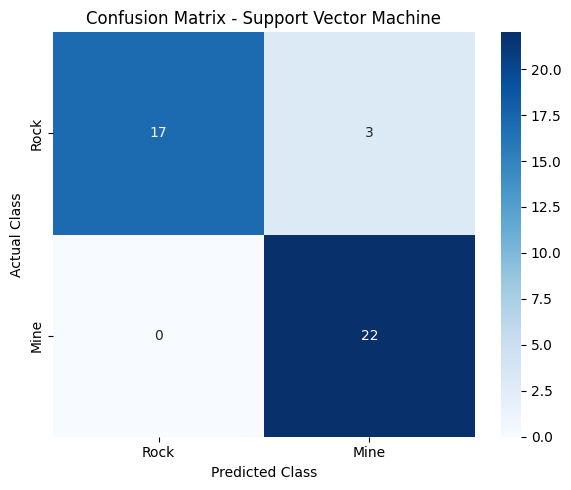

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Rock", "Mine"],
    yticklabels=["Rock", "Mine"]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

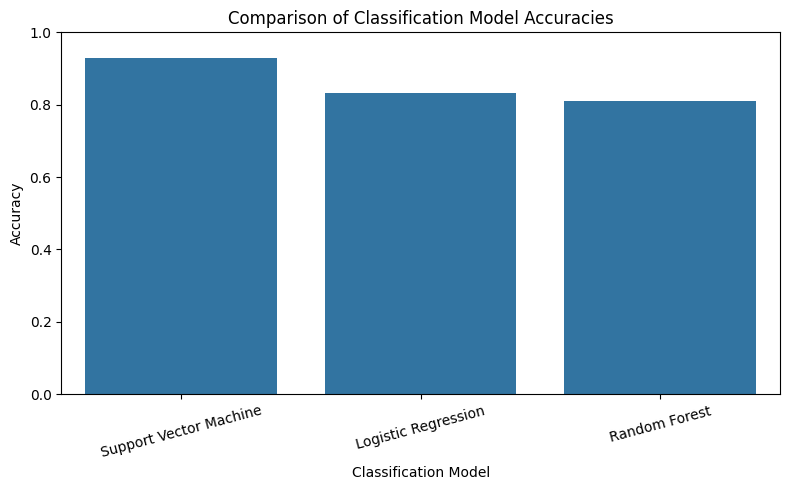

In [5]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.title("Comparison of Classification Model Accuracies")
plt.xlabel("Classification Model")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [6]:
import joblib
from pathlib import Path

# Save the best trained model
model_file = output_dir / "sonar_best_model.pkl"
joblib.dump(best_model, model_file)

# Save predictions and actual labels
predictions_df = pd.DataFrame({
    "Actual_Class": y_test.values,
    "Predicted_Class": y_pred
})

predictions_file = output_dir / "sonar_test_predictions.csv"
predictions_df.to_csv(predictions_file, index=False)

# Save model comparison results
results_file = output_dir / "sonar_model_comparison.csv"
results_df.to_csv(results_file, index=False)

print("Best model saved:", model_file)
print("Predictions saved:", predictions_file)
print("Model comparison saved:", results_file)

Best model saved: C:\Users\kavya\Connectionist Bench (Sonar, Mines vs. Rocks)\Sonar_Mines_vs_Rocks\sonar_best_model.pkl
Predictions saved: C:\Users\kavya\Connectionist Bench (Sonar, Mines vs. Rocks)\Sonar_Mines_vs_Rocks\sonar_test_predictions.csv
Model comparison saved: C:\Users\kavya\Connectionist Bench (Sonar, Mines vs. Rocks)\Sonar_Mines_vs_Rocks\sonar_model_comparison.csv
